In [34]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sakshigoyal7/credit-card-customers/BankChurners.csv


In [35]:
df=pd.read_csv('/kaggle/input/datasets/sakshigoyal7/credit-card-customers/BankChurners.csv')
df.head

<bound method NDFrame.head of        CLIENTNUM     Attrition_Flag  Customer_Age Gender  Dependent_count  \
0      768805383  Existing Customer            45      M                3   
1      818770008  Existing Customer            49      F                5   
2      713982108  Existing Customer            51      M                3   
3      769911858  Existing Customer            40      F                4   
4      709106358  Existing Customer            40      M                3   
...          ...                ...           ...    ...              ...   
10122  772366833  Existing Customer            50      M                2   
10123  710638233  Attrited Customer            41      M                2   
10124  716506083  Attrited Customer            44      F                1   
10125  717406983  Attrited Customer            30      M                2   
10126  714337233  Attrited Customer            43      F                2   

      Education_Level Marital_Status Income_C

Ici, je charge le jeu de données BankChurners et j'affiche un aperçu des premières lignes.

In [36]:
print('Taille du dataframe:',df.shape)
print('Type de chaque colonne du dataframe:')
df.info()
print('\nCombien y a t il de valeurs manquantes dans la colonne CLIENTNUM:',df['CLIENTNUM'].isna().sum())
print('\n Combien y a t il de doublons dans la colonne CLIENTNUM:',df['CLIENTNUM'].duplicated().sum())


Taille du dataframe: (10127, 23)
Type de chaque colonne du dataframe:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender     

Ici j'affiche le nombre de lignes et de colonnes du dataframe (10127 lignes et 23 colonnes), le type de chaque colonne et je vérifie la colonne CLIENTNUM qui ne contient aucune valeur manquante et aucun doublon.


In [37]:
# On ré-écrit le nom de toutes nos colonnes en minuscules
df.columns=df.columns.str.lower()
# On supprime la dernière et avant dernière colonne du dataframe df
df=df.iloc[:,:-2]
# on verifie qu'il y a bien 2 colonnes en moins
df.shape

(10127, 21)

Je viens de mettre les titres de mes colonnes en minuscules et j'ai supprimé les deux dernières colonnes qui avaient des noms trop longs et trop compliqués. On passe donc de 23 à 21 colonnes.

In [38]:
# Je crée la colonne churn qui va attribuer l'entier 0 s'il est parti ou l'entier 1 s'il est toujours dans l'entreprise
df['churn']=(df['attrition_flag']=='Attrited Customer').astype(int)
df['statut']=df['churn'].map({0:'Client actif',1:'Client parti'})
df['churn'].sum()

np.int64(1627)

ici je crée 2 colonnes supplémentaires. Je pars de la colonne attrition_flag pour créer la nouvelle colonne churn. Dans cette colonne churn, il n'y a que des 0 et des 1: 0 quand le client est parti (initialement nommé Attrited Customer) et 1 si le client est resté. Dans la colonne statut, j'ai écrit 'client actif là où il y avait des 1 et client parti là où il y avait des 0.

In [39]:
df['customer_age'].describe()
df['tranche_age']=pd.cut(df['customer_age'],bins=[20,40,60,80]).astype(str)
df['total_trans_ct'].describe()
df['activite']=pd.qcut(df['total_trans_ct'],3,labels=['Faible','Moyen','Forte']).astype(str)
df['activite'].value_counts()

activite
Faible    3458
Moyen     3375
Forte     3294
Name: count, dtype: int64

je viens de créer deux colonnes supplémentaires. La colonne tranche_age permet de regrouper les clients en 3 groupes d'age: entre 20 et 40 ans puis 40 - 60 ans puis 60 - 80 ans. La deuxième colonne activite permet de regrouper les clients en 3 groupes en fonction de leur activité bancaire: faible, moyenne ou forte.

In [40]:
display(df['education_level'].value_counts())
display(df['marital_status'].value_counts())
display(df['income_category'].value_counts())

education_level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64

marital_status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64

income_category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64

On remarque que dans les colonnes: education_level, marital_status et income_category, de nombreuses valeurs inconnues apparaissent ('unknown'). On ne peut pas supprimer les lignes correspondantes à ces valeurs inconnues car beaucoup trop de clients disparaitraient de la base de données. 


In [41]:
df.info()
df['attrition_flag'].describe 
round(df['churn'].mean()*100,1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   clientnum                 10127 non-null  int64  
 1   attrition_flag            10127 non-null  object 
 2   customer_age              10127 non-null  int64  
 3   gender                    10127 non-null  object 
 4   dependent_count           10127 non-null  int64  
 5   education_level           10127 non-null  object 
 6   marital_status            10127 non-null  object 
 7   income_category           10127 non-null  object 
 8   card_category             10127 non-null  object 
 9   months_on_book            10127 non-null  int64  
 10  total_relationship_count  10127 non-null  int64  
 11  months_inactive_12_mon    10127 non-null  int64  
 12  contacts_count_12_mon     10127 non-null  int64  
 13  credit_limit              10127 non-null  float64
 14  total_

np.float64(16.1)

ici je calcule le taux d'attrition global, en pourcentage arrondi à une décimale.
Comme la colionne churn n'a que des zeros et des uns, le taux d'attrition sera la moyenne des churns.

In [42]:
def taux_par(colonne):
    resultat=df.groupby(colonne)['clientnum'].count()
    resultat1=df.groupby(colonne)['churn'].sum()
    resultat2=df.groupby(colonne)['churn'].mean()
    return resultat, resultat1, resultat2

In [43]:
display(taux_par(df['card_category']))
display(taux_par(df['customer_age']))
display(taux_par(df['gender']))
display(taux_par(df['income_category']))
display(taux_par(df['total_trans_ct']))

(card_category
 Blue        9436
 Gold         116
 Platinum      20
 Silver       555
 Name: clientnum, dtype: int64,
 card_category
 Blue        1519
 Gold          21
 Platinum       5
 Silver        82
 Name: churn, dtype: int64,
 card_category
 Blue        0.160979
 Gold        0.181034
 Platinum    0.250000
 Silver      0.147748
 Name: churn, dtype: float64)

(customer_age
 26     78
 27     32
 28     29
 29     56
 30     70
 31     91
 32    106
 33    127
 34    146
 35    184
 36    221
 37    260
 38    303
 39    333
 40    361
 41    379
 42    426
 43    473
 44    500
 45    486
 46    490
 47    479
 48    472
 49    495
 50    452
 51    398
 52    376
 53    387
 54    307
 55    279
 56    262
 57    223
 58    157
 59    157
 60    127
 61     93
 62     93
 63     65
 64     43
 65    101
 66      2
 67      4
 68      2
 70      1
 73      1
 Name: clientnum, dtype: int64,
 customer_age
 26     6
 27     3
 28     1
 29     7
 30    15
 31    13
 32    17
 33    20
 34    19
 35    21
 36    24
 37    37
 38    47
 39    48
 40    64
 41    76
 42    62
 43    85
 44    84
 45    79
 46    82
 47    76
 48    85
 49    79
 50    71
 51    58
 52    58
 53    59
 54    69
 55    51
 56    43
 57    33
 58    24
 59    40
 60    13
 61    17
 62    17
 63     8
 64     5
 65     9
 66     1
 67     0
 68     1
 70     0
 73  

(gender
 F    5358
 M    4769
 Name: clientnum, dtype: int64,
 gender
 F    930
 M    697
 Name: churn, dtype: int64,
 gender
 F    0.173572
 M    0.146152
 Name: churn, dtype: float64)

(income_category
 $120K +            727
 $40K - $60K       1790
 $60K - $80K       1402
 $80K - $120K      1535
 Less than $40K    3561
 Unknown           1112
 Name: clientnum, dtype: int64,
 income_category
 $120K +           126
 $40K - $60K       271
 $60K - $80K       189
 $80K - $120K      242
 Less than $40K    612
 Unknown           187
 Name: churn, dtype: int64,
 income_category
 $120K +           0.173315
 $40K - $60K       0.151397
 $60K - $80K       0.134807
 $80K - $120K      0.157655
 Less than $40K    0.171862
 Unknown           0.168165
 Name: churn, dtype: float64)

(total_trans_ct
 10     4
 11     2
 12     4
 13     5
 14     9
       ..
 131    6
 132    1
 134    1
 138    1
 139    1
 Name: clientnum, Length: 126, dtype: int64,
 total_trans_ct
 10     4
 11     1
 12     4
 13     3
 14     8
       ..
 131    0
 132    0
 134    0
 138    0
 139    0
 Name: churn, Length: 126, dtype: int64,
 total_trans_ct
 10     1.000000
 11     0.500000
 12     1.000000
 13     0.600000
 14     0.888889
          ...   
 131    0.000000
 132    0.000000
 134    0.000000
 138    0.000000
 139    0.000000
 Name: churn, Length: 126, dtype: float64)

Concernant les 9436 clients qui possèdent une carte bleue, le taux d'attrition est de 16,1%.
Le taux d'attrition des 727 clients ayant des revenus de plus de 120 000 dollars est de 17,33%.

Le taux d'attrition des 5358 femmes ayant un ou des comptes dans cette banque est de 17,36%.

L'idee du code ci-dessous est de comparer le comportement des clients qui sont partis (churn) par rapport à ceux qui sont restés en calculant des moyennes.
Je crée donc d'abord une variable comprenant la liste des comportements à évaluer et ensuite, à l'aide d'un groupby(churn) je vais appliquer comme un masque sur mes colonnes comportement qui me permettra de comparer ces moyennes (moyenne du nombre de transactions par exemple) entre les clients partis et ceux qui sont restés.

In [44]:
comportement=['total_trans_amt','total_trans_ct','total_revolving_bal','months_inactive_12_mon','contacts_count_12_mon','avg_utilization_ratio']
resultat=df.groupby('churn')[comportement].mean().round(2)
display(resultat)

,total_trans_amt,total_trans_ct,total_revolving_bal,months_inactive_12_mon,contacts_count_12_mon,avg_utilization_ratio
churn,,,,,,
0,4654.66,68.67,1256.60,2.27,2.36,0.30
1,3095.03,44.93,672.82,2.69,2.97,0.16


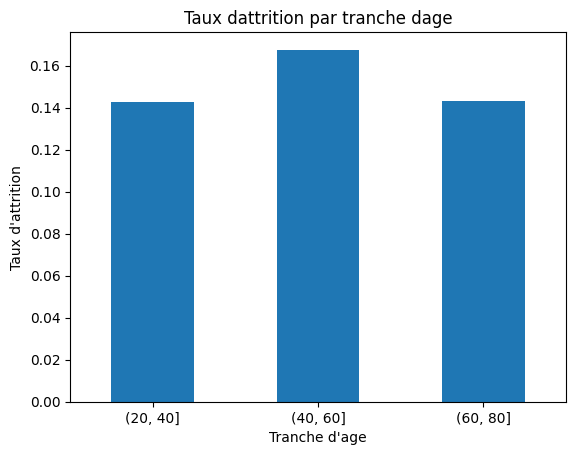

In [45]:
import matplotlib.pyplot as plt
taux_par(df['tranche_age'])[2].plot(kind='bar',title='Taux d''attrition par tranche d''age',rot=0)
plt.xlabel("Tranche d'age")
plt.ylabel("Taux d'attrition")
plt.show()

On déduit de cet histogramme que la tranche d'age la plus touchée et la tranche 40-60 ans avec 16% des clients de cette tranche qui quitte la banque. Il s'agit de la population la plus instable en termes de fidélité bancaire.
Les clients des tranches 20-40 et 60-80 affichent exactement le même taux d'attrition de 14%.
Le pic des 40-60 ans est supérieur d'environ 2 points de pourcentage par rapport aux deux autres tranches d'age, ce qui est une faible variation.
Ce graphique met en evidence une correlation statistique entre age et départ mais en aucun cas une causalité directe.
Ce graphique ne permet pas non plus de voir l'évolution au cours du temps de cette relation ou de prendre en compte l'ancienneté du client au sein de la banque.

In [46]:
import sqlite3
conn=sqlite3.connect('bank.db')
df.to_sql('clients',conn,if_exists='replace',index=False)

10127

Dans la partie ci-dessus j'ai exporté mon tableau db nettoyé avec panda dans un nouveau fichier nommé bank.db. A l'interieur de ce fichier, le tableau s'appelle "clients". Pour la suite, les commandes SQL seront écrites à l'intérieur du code Python.

In [47]:
df_global=pd.read_sql('SELECT COUNT (*) AS nombre_clients, SUM(churn) AS nombre_partants, ROUND(100.0*AVG(churn),1) AS taux_pourcentage FROM clients ', conn)
display(df_global)

,nombre_clients,nombre_partants,taux_pourcentage
0,10127,1627,16.1


Les lignes de code ci-dessus représentent une requête qui renvoie le nombre de clients, le nombre de partis et le taux en % (une décimale).

In [48]:
df_carte=pd.read_sql("""
     SELECT card_category, COUNT (*) AS nombre_clients, SUM(churn) AS nombre_partants, ROUND(100.0*AVG(churn),1) AS taux_pourcentage 
     FROM clients 
     GROUP BY card_category 
     ORDER BY taux_pourcentage DESC
     """, conn)
display(df_carte)

,card_category,nombre_clients,nombre_partants,taux_pourcentage
0,Platinum,20,5,25.0
1,Gold,116,21,18.1
2,Blue,9436,1519,16.1
3,Silver,555,82,14.8


Pour interpreter le tableau ci-dessus, on pourrait dire par exemple que 20 clients ont la carte Platinium et aue parmi eux, 5 ont quitté la banque soit un pourcentage de 25% des clients possédant cette carte.

In [49]:
df_tranches=pd.read_sql("""
    SELECT COUNT(*) AS nombre_clients, ROUND(100.0*AVG(churn),1) AS taux_pourcentage,
CASE
when customer_age<40 THEN 'jeunes'
when customer_age<60 THEN 'plus tres jeunes'
ELSE 'clients âgés'
END AS tranche_age
FROM clients
GROUP BY tranche_age
""", conn)
display(df_tranches)

,nombre_clients,taux_pourcentage,tranche_age
0,2397,14.3,plus tres jeunes
1,7325,16.8,plus tres jeunes
2,405,14.3,clients âgés


Grâce au code precedent, on retrouve les tranches d'ages calculées avec Python Panda au dessus: les clients entre 40 et 60 ans sont ceux qui quittent le plus la banque.

In [50]:
#df.info()
df['income_category'].head()
df_category=pd.read_sql("""
WITH tableau_intermediaire AS(
SELECT income_category, ROUND(100.0*AVG(churn),1) AS taux_pourcentage FROM clients
group by income_category 
HAVING COUNT(clientnum) >200)

SELECT income_category, taux_pourcentage,
RANK() OVER (ORDER BY taux_pourcentage DESC) AS rang
FROM tableau_intermediaire
ORDER BY rang; 
""", conn)
display(df_category)

,income_category,taux_pourcentage,rang
0,$120K +,17.3,1
1,Less than $40K,17.2,2
2,Unknown,16.8,3
3,$80K - $120K,15.8,4
4,$40K - $60K,15.1,5
5,$60K - $80K,13.5,6


Dans le code précédent, le calcul est fait en 2 etapes. D'abord je crée un tableau intermédiaire qui me permettra d'obtenir les deux premières colonnes de mon tableau résultat: la colonne income_category (dans laquelle ne figure que les catégories ayant plus de 200 clients) et la colonne taux_pourcentage, dans laquelle figure le pourcentage de clients ayant quitté la banque par catégorie.
J'ai ensuite crée la dernière colonne "rang", qui donne un rang aux catégories classées de la catégorie au plus grand pourcentage de départ de la banque, au pourcentage le plus petit. 
On remarque qu'avec le filtre appliqué, la catégorie Unknown reste dans le tableau.

Maintenant on va comparer les resulats obtenus avec Python Panda et ceux obtenus avec SQL. Le code ci-dessous fait exactement la même chose avec SQL et Panda et donne exactement les mêmes resultats, ce qui montre que la bonne démarche est utilisée.



In [51]:
sql="""
SELECT card_category, COUNT(*) AS nb_clients, SUM(churn) AS nb_partis, ROUND(100.0*AVG(CHURN),1) AS taux 
FROM clients
GROUP BY card_category
ORDER BY taux DESC
"""

resultat_sql=pd.read_sql(sql,conn)

resultat_pandas=df.groupby('card_category').agg(
    nb_clients=('churn','count'),
    nb_partis=('churn','sum'),
    taux=('churn','mean')).reset_index()

resultat_pandas['taux']=(resultat_pandas['taux']*100).round(1)
resultat_pandas=resultat_pandas.sort_values('taux',ascending=False)

print(resultat_sql)
print(resultat_pandas)

  card_category  nb_clients  nb_partis  taux
0      Platinum          20          5  25.0
1          Gold         116         21  18.1
2          Blue        9436       1519  16.1
3        Silver         555         82  14.8
  card_category  nb_clients  nb_partis  taux
2      Platinum          20          5  25.0
1          Gold         116         21  18.1
0          Blue        9436       1519  16.1
3        Silver         555         82  14.8


On retrouve les mêmes résultats sur chaque tableau. Pou rla carte Blue, 9436 clients, 1519 ont quitté la banque et un taux de 16.1%.Pour la Platinium, 20 clients, 5 partis et un taux de 25.0%. A noter que ce dernier taux ne reposant que sur 20 clients, il n'est pas très fiable. 